In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("UC08-Analyses-KPI")
    .master("local[1]")
    .getOrCreate()
)

print("Version Spark :", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/19 16:24:02 WARN Utils: Your hostname, Doralie, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/19 16:24:02 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/doralie/retail-intelligence-platform/.venv/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/19 16:24:03 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Version Spark : 4.3.0


In [3]:
from pathlib import Path

projet = Path.home() / "retail-intelligence-platform"

ventes = spark.read.parquet(
    (projet / "UC06/silver/store_sales").as_uri()
)

articles = spark.read.parquet(
    (projet / "UC06/silver/item").as_uri()
)

ca_categories = spark.read.parquet(
    (projet / "UC06/gold/ca_par_categorie").as_uri()
)

print("Données Silver et Gold chargées avec succès !")

Données Silver et Gold chargées avec succès !


In [4]:
print("Ventes Silver :", ventes.count())
print("Articles Silver :", articles.count())
print("Catégories Gold :", ca_categories.count())

Ventes Silver : 667579
Articles Silver : 17820
Catégories Gold : 9


Nous allons calculer les indicateurs demandés par mon professeur :
KPI	Formule	Source
Chiffre d'affaires net	SUM(ss_net_paid)	Silver — ventes
Quantité vendue	SUM(ss_quantity)	Silver — ventes
Nombre de lignes de vente	COUNT(*)	Silver — ventes

Ces trois indicateurs mesurent respectivement le montant net enregistré, les unités vendues et le volume de lignes de vente. Attention : le nombre de lignes n'est pas nécessairement le nombre de transactions distinctes.

In [5]:
from pyspark.sql import functions as F

kpi_globaux = ventes.agg(
    F.sum("ss_net_paid").alias("chiffre_affaires_net"),
    F.sum("ss_quantity").alias("quantite_totale"),
    F.count("*").alias("nombre_lignes_vente")
)

kpi_globaux.show(truncate=False)

+--------------------+---------------+-------------------+
|chiffre_affaires_net|quantite_totale|nombre_lignes_vente|
+--------------------+---------------+-------------------+
|1150529586.37       |33755474       |667579             |
+--------------------+---------------+-------------------+



### ca par categorie


In [6]:
ca_categories.orderBy(
    F.desc("chiffre_affaires_net")
).show(20, truncate=False)

+------------------------+--------------------+---------------+-------------------+
|categorie               |chiffre_affaires_net|quantite_vendue|nombre_lignes_vente|
+------------------------+--------------------+---------------+-------------------+
|Music                   |519666693.84        |15238374       |301236             |
|Books                   |307151503.25        |9007511        |177671             |
|Movies & TV             |74735891.89         |2189279        |43376              |
|Clothing & Accessories  |56754855.82         |1640550        |32372              |
|Electronics             |55715087.49         |1632098        |32619              |
|Home & Kitchen          |41260511.11         |1226839        |24380              |
|Sports & Outdoors       |40926938.33         |1209305        |23911              |
|Toys & Games            |27437825.33         |809999         |16121              |
|Tools & Home Improvement|26880279.31         |801519         |15893        

In [7]:
kpi_silver = kpi_globaux.first()

kpi_gold = ca_categories.agg(
    F.sum("chiffre_affaires_net").alias("ca"),
    F.sum("quantite_vendue").alias("quantite"),
    F.sum("nombre_lignes_vente").alias("lignes")
).first()

print("CA Silver :", kpi_silver["chiffre_affaires_net"])
print("CA Gold   :", kpi_gold["ca"])

print("Quantité Silver :", kpi_silver["quantite_totale"])
print("Quantité Gold   :", kpi_gold["quantite"])

print("Lignes Silver :", kpi_silver["nombre_lignes_vente"])
print("Lignes Gold   :", kpi_gold["lignes"])

CA Silver : 1150529586.37
CA Gold   : 1150529586.37
Quantité Silver : 33755474
Quantité Gold   : 33755474
Lignes Silver : 667579
Lignes Gold   : 667579


### Statistiques descriptives

In [8]:
from pyspark.sql import functions as F

statistiques = ventes.agg(
    F.count("*").alias("nombre_ventes"),
    F.min("ss_net_paid").alias("montant_min"),
    F.max("ss_net_paid").alias("montant_max"),
    F.avg("ss_net_paid").alias("montant_moyen"),
    F.expr(
        "percentile_approx(ss_net_paid, 0.5)"
    ).alias("montant_median_approx"),
    F.sum("ss_net_paid").alias("montant_total"),
    F.min("ss_quantity").alias("quantite_min"),
    F.max("ss_quantity").alias("quantite_max"),
    F.avg("ss_quantity").alias("quantite_moyenne")
)

statistiques.show(truncate=False)

+-------------+-----------+-----------+-------------+---------------------+-------------+------------+------------+------------------+
|nombre_ventes|montant_min|montant_max|montant_moyen|montant_median_approx|montant_total|quantite_min|quantite_max|quantite_moyenne  |
+-------------+-----------+-----------+-------------+---------------------+-------------+------------+------------+------------------+
|667579       |0.00       |18745.00   |1723.435858  |878.27               |1150529586.37|1           |100         |50.564014146640325|
+-------------+-----------+-----------+-------------+---------------------+-------------+------------+------------+------------------+



### Repartition du chiffre d'affaire par categorie

In [9]:
ca_total = ca_categories.agg(
    F.sum("chiffre_affaires_net")
).first()[0]

repartition = (
    ca_categories
    .withColumn(
        "part_ca_pct",
        F.round(
            F.col("chiffre_affaires_net") / F.lit(ca_total) * 100,
            2
        )
    )
    .orderBy(F.desc("part_ca_pct"))
)

repartition.show(truncate=False)

+------------------------+--------------------+---------------+-------------------+-----------+
|categorie               |chiffre_affaires_net|quantite_vendue|nombre_lignes_vente|part_ca_pct|
+------------------------+--------------------+---------------+-------------------+-----------+
|Music                   |519666693.84        |15238374       |301236             |45.17      |
|Books                   |307151503.25        |9007511        |177671             |26.70      |
|Movies & TV             |74735891.89         |2189279        |43376              |6.50       |
|Clothing & Accessories  |56754855.82         |1640550        |32372              |4.93       |
|Electronics             |55715087.49         |1632098        |32619              |4.84       |
|Home & Kitchen          |41260511.11         |1226839        |24380              |3.59       |
|Sports & Outdoors       |40926938.33         |1209305        |23911              |3.56       |
|Toys & Games            |27437825.33   

Visualisation 1 : chiffre d'affaires par catégorie

/home/doralie/retail-intelligence-platform/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/doralie/retail-intelligence-platform/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


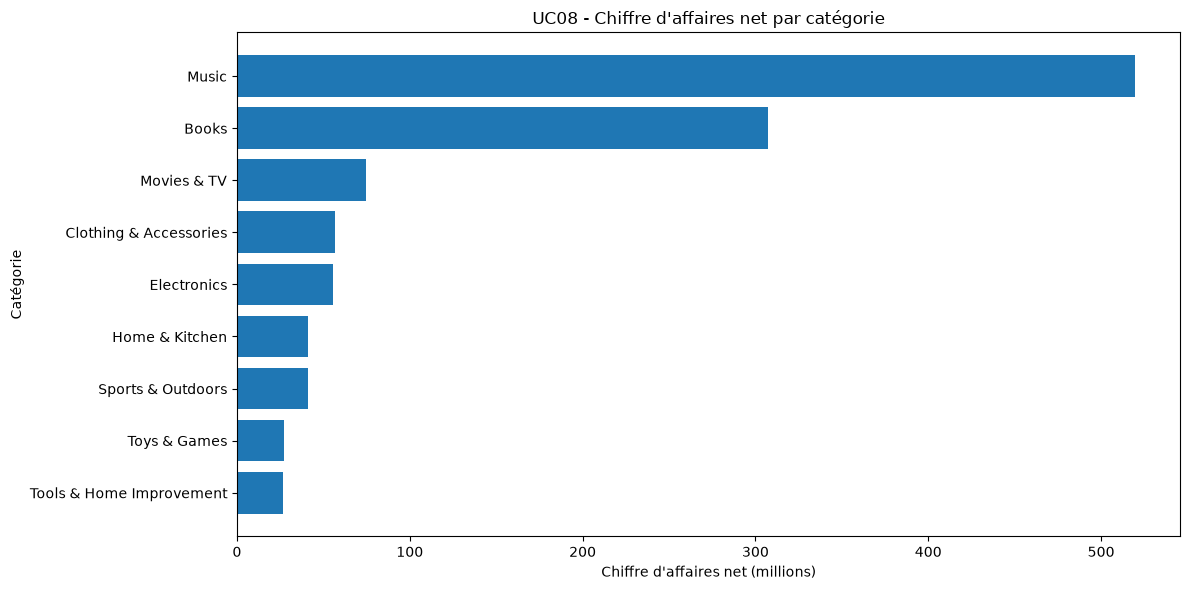

In [10]:
import matplotlib.pyplot as plt

df_ca = repartition.toPandas()

plt.figure(figsize=(12, 6))

plt.barh(
    df_ca["categorie"],
    df_ca["chiffre_affaires_net"] / 1_000_000
)

plt.xlabel("Chiffre d'affaires net (millions)")
plt.ylabel("Catégorie")
plt.title("UC08 - Chiffre d'affaires net par catégorie")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    str(projet / "UC08/visualisations/visualisation_1.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Visualisation 2 : quantités vendues par catégorie

/home/doralie/retail-intelligence-platform/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/doralie/retail-intelligence-platform/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


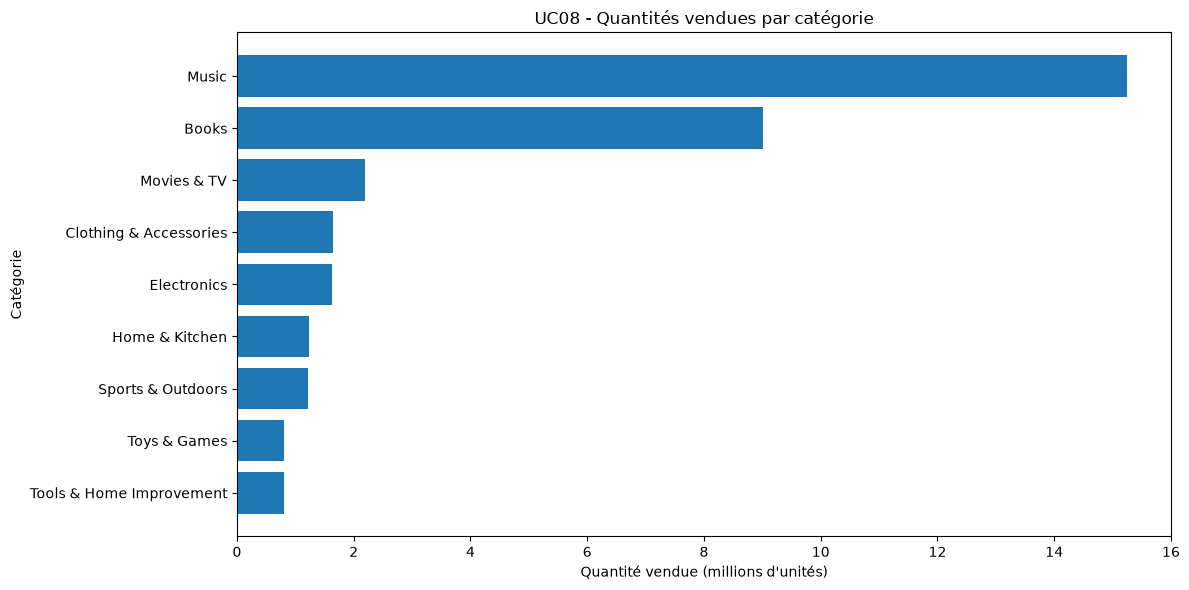

In [11]:
df_quantites = (
    ca_categories
    .orderBy(F.desc("quantite_vendue"))
    .toPandas()
)

plt.figure(figsize=(12, 6))

plt.barh(
    df_quantites["categorie"],
    df_quantites["quantite_vendue"] / 1_000_000
)

plt.xlabel("Quantité vendue (millions d'unités)")
plt.ylabel("Catégorie")
plt.title("UC08 - Quantités vendues par catégorie")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    str(projet / "UC08/visualisations/visualisation_2.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [12]:
from pathlib import Path

dossier_preuves = projet / "UC08/preuves/uc08"
dossier_preuves.mkdir(parents=True, exist_ok=True)

datasets = {
    "Silver - store_sales": ventes,
    "Silver - item": articles,
    "Gold - ca_par_categorie": ca_categories
}

with open(dossier_preuves / "schemas_donnees.txt", "w", encoding="utf-8") as f:
    for nom, df in datasets.items():
        f.write(f"\n{'=' * 60}\n")
        f.write(f"{nom}\n")
        f.write(f"{'=' * 60}\n")
        f.write(df._jdf.schema().treeString())
        f.write("\n")

print("Schémas exportés avec succès !")

Schémas exportés avec succès !


In [13]:
# Export des trois KPI globaux
kpi_globaux.toPandas().to_csv(
    dossier_preuves / "kpi_globaux.csv",
    index=False
)

# Export des statistiques descriptives
statistiques.toPandas().to_csv(
    dossier_preuves / "statistiques_descriptives.csv",
    index=False
)

# Export des résultats par catégorie
repartition.toPandas().to_csv(
    dossier_preuves / "kpi_par_categorie.csv",
    index=False
)

print("KPI et statistiques exportés avec succès !")

/home/doralie/retail-intelligence-platform/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/doralie/retail-intelligence-platform/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/home/doralie/retail-intelligence-platform/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. 

KPI et statistiques exportés avec succès !


/home/doralie/retail-intelligence-platform/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/doralie/retail-intelligence-platform/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
